# pXRF Scan Demo

This notebook demonstrates a practical workflow for loading pXRF (portable X-ray fluorescence) data exports with the `scandrivers` package and exploring the resulting elemental composition data.

In [46]:
# Install the package if needed
# %pip install -e ..

from pathlib import Path
import importlib

import scandrivers

# Reload the local package when this notebook kernel predates a package edit.
scandrivers = importlib.reload(scandrivers)
from scandrivers import demo_data_path, load_data

# Access demo data using the convenience helper
data_path = demo_data_path("pxrf", "Final", "pXRF Readings (Trench1to6).xlsx")
print(f"Data path: {data_path}")
print(f"File exists: {data_path.exists()}")


Data path: /mnt/DCDCDB23DCDAF72C/wcarleton/Projects/MagSus/src/scandrivers/demo_data/pxrf/Final/pXRF Readings (Trench1to6).xlsx
File exists: True


## Load pXRF data from the finalized export

This section locates and loads the pXRF scan using the package loader.

In [47]:
df = load_data(data_path, driver="pxrf")
df.head()

,reading_no,time,duration,units,sequence,flags,sample,test_type,mo,mo_error,...,p_cps_ua,si,si_error,si_cps_ua,cl,cl_error,cl_cps_ua,mg,mg_error,mg_cps_ua
0,57,2024-04-15 10:37:00,120.43,ppm,Final,NaN,KKT1-0CM,Soil,7.88,1.87,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,58,2024-04-15 10:39:00,120.15,ppm,Final,NaN,KKT1-0CM,Soil,7.5,1.85,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,59,2024-04-15 10:41:00,120.14,ppm,Final,NaN,KKT1-0CM,Soil,7.24,1.85,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,60,2024-04-15 10:47:00,202.00,%,Final,ModCF Set 1-3mm,KKT1-0CM,Mining,NaN,NaN,...,0.304,15.360,0.236,3.654,<LOD,0.004,0.382,<LOD,0.337,0.022
4,61,2024-04-15 10:51:00,200.10,%,Final,ModCF Set 1-3mm,KKT1-0CM,Mining,NaN,NaN,...,0.317,15.411,0.235,3.669,<LOD,0.004,0.370,<LOD,0.299,0.017


## Inspect loaded data

Examine the metadata columns, data shape, and basic properties of the loaded pXRF readings.

In [48]:
print(f"DataFrame shape: {df.shape}")
print(f"\nColumns: {df.columns.tolist()}")
print(f"\nMetadata columns:")
metadata_cols = ["reading_no", "time", "duration", "units", "sample", "test_type"]
df[metadata_cols].head(10)

DataFrame shape: (366, 134)

Columns: ['reading_no', 'time', 'duration', 'units', 'sequence', 'flags', 'sample', 'test_type', 'mo', 'mo_error', 'mo_cps_ua', 'zr', 'zr_error', 'zr_cps_ua', 'sr', 'sr_error', 'sr_cps_ua', 'u', 'u_error', 'u_cps_ua', 'rb', 'rb_error', 'rb_cps_ua', 'th', 'th_error', 'th_cps_ua', 'pb', 'pb_error', 'pb_cps_ua', 'au', 'au_error', 'au_cps_ua', 'se', 'se_error', 'se_cps_ua', 'as', 'as_error', 'as_cps_ua', 'hg', 'hg_error', 'hg_cps_ua', 'zn', 'zn_error', 'zn_cps_ua', 'w', 'w_error', 'w_cps_ua', 'cu', 'cu_error', 'cu_cps_ua', 'ni', 'ni_error', 'ni_cps_ua', 'co', 'co_error', 'co_cps_ua', 'fe', 'fe_error', 'fe_cps_ua', 'mn', 'mn_error', 'mn_cps_ua', 'cr', 'cr_error', 'cr_cps_ua', 'v', 'v_error', 'v_cps_ua', 'ti', 'ti_error', 'ti_cps_ua', 'sc', 'sc_error', 'sc_cps_ua', 'ca', 'ca_error', 'ca_cps_ua', 'k', 'k_error', 'k_cps_ua', 's', 's_error', 's_cps_ua', 'ba', 'ba_error', 'ba_cps_ua', 'cs', 'cs_error', 'cs_cps_ua', 'te', 'te_error', 'te_cps_ua', 'sb', 'sb_error', 'sb

,reading_no,time,duration,units,sample,test_type
0,57,2024-04-15 10:37:00,120.43,ppm,KKT1-0CM,Soil
1,58,2024-04-15 10:39:00,120.15,ppm,KKT1-0CM,Soil
2,59,2024-04-15 10:41:00,120.14,ppm,KKT1-0CM,Soil
3,60,2024-04-15 10:47:00,202.00,%,KKT1-0CM,Mining
4,61,2024-04-15 10:51:00,200.10,%,KKT1-0CM,Mining
5,62,2024-04-15 10:55:00,201.18,%,KKT1-0CM,Mining
6,73,2024-04-15 14:04:00,120.42,ppm,KKT1-10CM,Soil
7,74,2024-04-15 14:06:00,120.73,ppm,KKT1-10CM,Soil
8,75,2024-04-15 14:08:00,120.39,ppm,KKT1-10CM,Soil
9,70,2024-04-15 13:52:00,201.20,%,KKT1-10CM,Mining


## Parse archaeological sample metadata

The 'sample' column contains encoded information about the excavation context. Sample codes follow the pattern `{SITE}{UNIT}-{DEPTH}` (e.g., 'KKT1-0CM'):
- **Site code** (2 letters): KK = Koh Ker
- **Trench/Unit** (T + number): T1 = Trench 1
- **Depth below surface** (in cm): 0CM = sample top at 0 cm below surface

The soil samples were block sampled from excavation trench walls in 5 cm contiguous blocks spaced 5 cm apart vertically. The 'dbs_cm' (depth below surface) refers to the top of each sample block. Parsing these codes allows us to organize and filter readings by excavation unit and depth for stratigraphic analysis.

In [49]:
import re

# Define a function to parse archaeological sample codes
def parse_sample_code(sample_code):
    """Parse archaeological sample codes like 'KKT1-0CM'
    
    Format: {SITE}{TRENCH}-{DEPTH_CM}
    Example: 'KKT1-0CM' → site='KK', trench_unit='T1', dbs_cm=0
    
    Args:
        sample_code: Sample code string (e.g., 'KKT1-0CM')
    
    Returns:
        Tuple of (site, trench_unit, dbs_cm) or (None, None, None) if parsing fails
    """
    pattern = r'^([A-Z]{2})(T\d+)-(\d+)CM$'
    match = re.match(pattern, str(sample_code), re.IGNORECASE)
    
    if match:
        site = match.group(1)
        trench = match.group(2)
        dbs_cm = int(match.group(3))
        return site, trench, dbs_cm
    return None, None, None

# Apply parsing to extract archaeological metadata
df[['site', 'trench_unit', 'dbs_cm']] = df['sample'].apply(
    lambda x: pd.Series(parse_sample_code(x))
)

# Add a notes column explaining the sampling methodology
df['notes'] = (
    'Bulk processed soil from 5cm blocks block-sampled from excavation trench walls. '
    'Sample blocks are spaced 5cm apart vertically. '
    'dbs_cm = depth below surface at top of sample block.'
)

# Display parsed results
print("Archaeological sample metadata parsing:")
print(df[['sample', 'site', 'trench_unit', 'dbs_cm', 'units', 'test_type']].head(12))

print(f"\n\nDepth range: {df['dbs_cm'].min():.0f}-{df['dbs_cm'].max():.0f} cm")
print(f"Sampling interval: 5 cm")
print(f"Sites represented: {[s for s in df['site'].dropna().unique().tolist()]}")
print(f"Trench/units represented: {sorted([t for t in df['trench_unit'].dropna().unique().tolist()])}")
print(f"\nDataFrame now includes site, trench_unit, dbs_cm, and notes columns for stratified analysis.")

Archaeological sample metadata parsing:
       sample site trench_unit  dbs_cm units test_type
0    KKT1-0CM   KK          T1     0.0   ppm      Soil
1    KKT1-0CM   KK          T1     0.0   ppm      Soil
2    KKT1-0CM   KK          T1     0.0   ppm      Soil
3    KKT1-0CM   KK          T1     0.0     %    Mining
4    KKT1-0CM   KK          T1     0.0     %    Mining
5    KKT1-0CM   KK          T1     0.0     %    Mining
6   KKT1-10CM   KK          T1    10.0   ppm      Soil
7   KKT1-10CM   KK          T1    10.0   ppm      Soil
8   KKT1-10CM   KK          T1    10.0   ppm      Soil
9   KKT1-10CM   KK          T1    10.0     %    Mining
10  KKT1-10CM   KK          T1    10.0     %    Mining
11  KKT1-10CM   KK          T1    10.0     %    Mining


Depth range: 0-130 cm
Sampling interval: 5 cm
Sites represented: ['KK']
Trench/units represented: ['T1', 'T2', 'T3', 'T4', 'T5', 'T6']

DataFrame now includes site, trench_unit, dbs_cm, and notes columns for stratified analysis.


/tmp/ipykernel_474184/1024638044.py:27: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[['site', 'trench_unit', 'dbs_cm']] = df['sample'].apply(
/tmp/ipykernel_474184/1024638044.py:32: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['notes'] = (


## Explore measurement units

The pXRF data contains two types of measurements: Soil readings in ppm and Mining readings in %. Let's examine this distinction.

In [50]:
# Count readings by units and test type
units_summary = df.groupby(["units", "test_type"]).size().reset_index(name="count")
print("Readings by units and test type:")
print(units_summary)

# Separate soil (ppm) and mining (%) readings
soil_readings = df[df["units"] == "ppm"]
mining_readings = df[df["units"] == "%"]

print(f"\nSoil readings (ppm): {len(soil_readings)}")
print(f"Mining readings (%): {len(mining_readings)}")

Readings by units and test type:
  units test_type  count
0     %    Mining    183
1   ppm      Soil    183

Soil readings (ppm): 183
Mining readings (%): 183


## Examine element columns and LOD values

The pXRF data contains measurements for 42 elements, each with concentration, error, and CPS/ua columns. Many measurements include <LOD (less than limit of detection) markers.

In [51]:
# Identify element columns (exclude metadata)
metadata_cols = ["reading_no", "time", "duration", "units", "sequence", "flags", "sample", "test_type"]
element_cols = [col for col in df.columns if col not in metadata_cols]

print(f"Total element-related columns: {len(element_cols)}")
print(f"\nExample element columns: {element_cols[:12]}")

# Check for LOD values in element columns
lod_count = 0
for col in element_cols:
    for val in df[col]:
        if isinstance(val, str) and "<lod" in val.lower():
            lod_count += 1

print(f"\nTotal <LOD values in dataset: {lod_count}")

Total element-related columns: 130

Example element columns: ['mo', 'mo_error', 'mo_cps_ua', 'zr', 'zr_error', 'zr_cps_ua', 'sr', 'sr_error', 'sr_cps_ua', 'u', 'u_error', 'u_cps_ua']

Total <LOD values in dataset: 6492


## Filter and analyze a specific element

Let's focus on Iron (Fe) as an example and analyze its concentration across soil samples.

In [52]:
import pandas as pd
import numpy as np

# Extract Fe measurements from soil samples
fe_soil = soil_readings[["reading_no", "sample", "fe", "fe_error"]].copy()

# Convert Fe to numeric, handling any <LOD values
fe_soil["fe_numeric"] = pd.to_numeric(fe_soil["fe"], errors="coerce")
fe_soil["has_lod"] = fe_soil["fe"].astype(str).str.contains("<lod", case=False, na=False)

print("Iron (Fe) measurements in soil samples:")
print(fe_soil.head(10))

print(f"\nSoil Fe statistics (ppm):")
print(fe_soil["fe_numeric"].describe())

print(f"\nReadings with <LOD: {fe_soil['has_lod'].sum()}")

Iron (Fe) measurements in soil samples:
    reading_no     sample        fe  fe_error  fe_numeric  has_lod
0           57   KKT1-0CM   9634.93     94.27     9634.93    False
1           58   KKT1-0CM   9587.45     93.65     9587.45    False
2           59   KKT1-0CM   9573.34     93.42     9573.34    False
6           73  KKT1-10CM  18394.65    131.55    18394.65    False
7           74  KKT1-10CM  18435.24    131.27    18435.24    False
8           75  KKT1-10CM  18368.45    131.65    18368.45    False
12          84  KKT1-20CM  22885.93    145.43    22885.93    False
13          85  KKT1-20CM  22839.65    145.12    22839.65    False
14          86  KKT1-20CM  22757.43    143.64    22757.43    False
18          90  KKT1-30CM  44227.32    215.49    44227.32    False

Soil Fe statistics (ppm):
count      183.000000
mean     18129.309617
std      11795.230883
min       1454.100000
25%       9580.395000
50%      15934.990000
75%      22862.790000
max      54291.110000
Name: fe_numeric, dt

## Visualize element concentration distribution

Plot the Iron concentrations for soil samples to visualize the elemental distribution.

Analyzing: T1
Y-axis scale: logarithmic
Depths sampled: [0, 10, 20, 30, 40, 50, 60, 70, 80, 90] cm
Number of depth samples: 10
Consistent element suite: ['AS', 'CA', 'CU', 'FE', 'K', 'MN', 'PB', 'ZR']


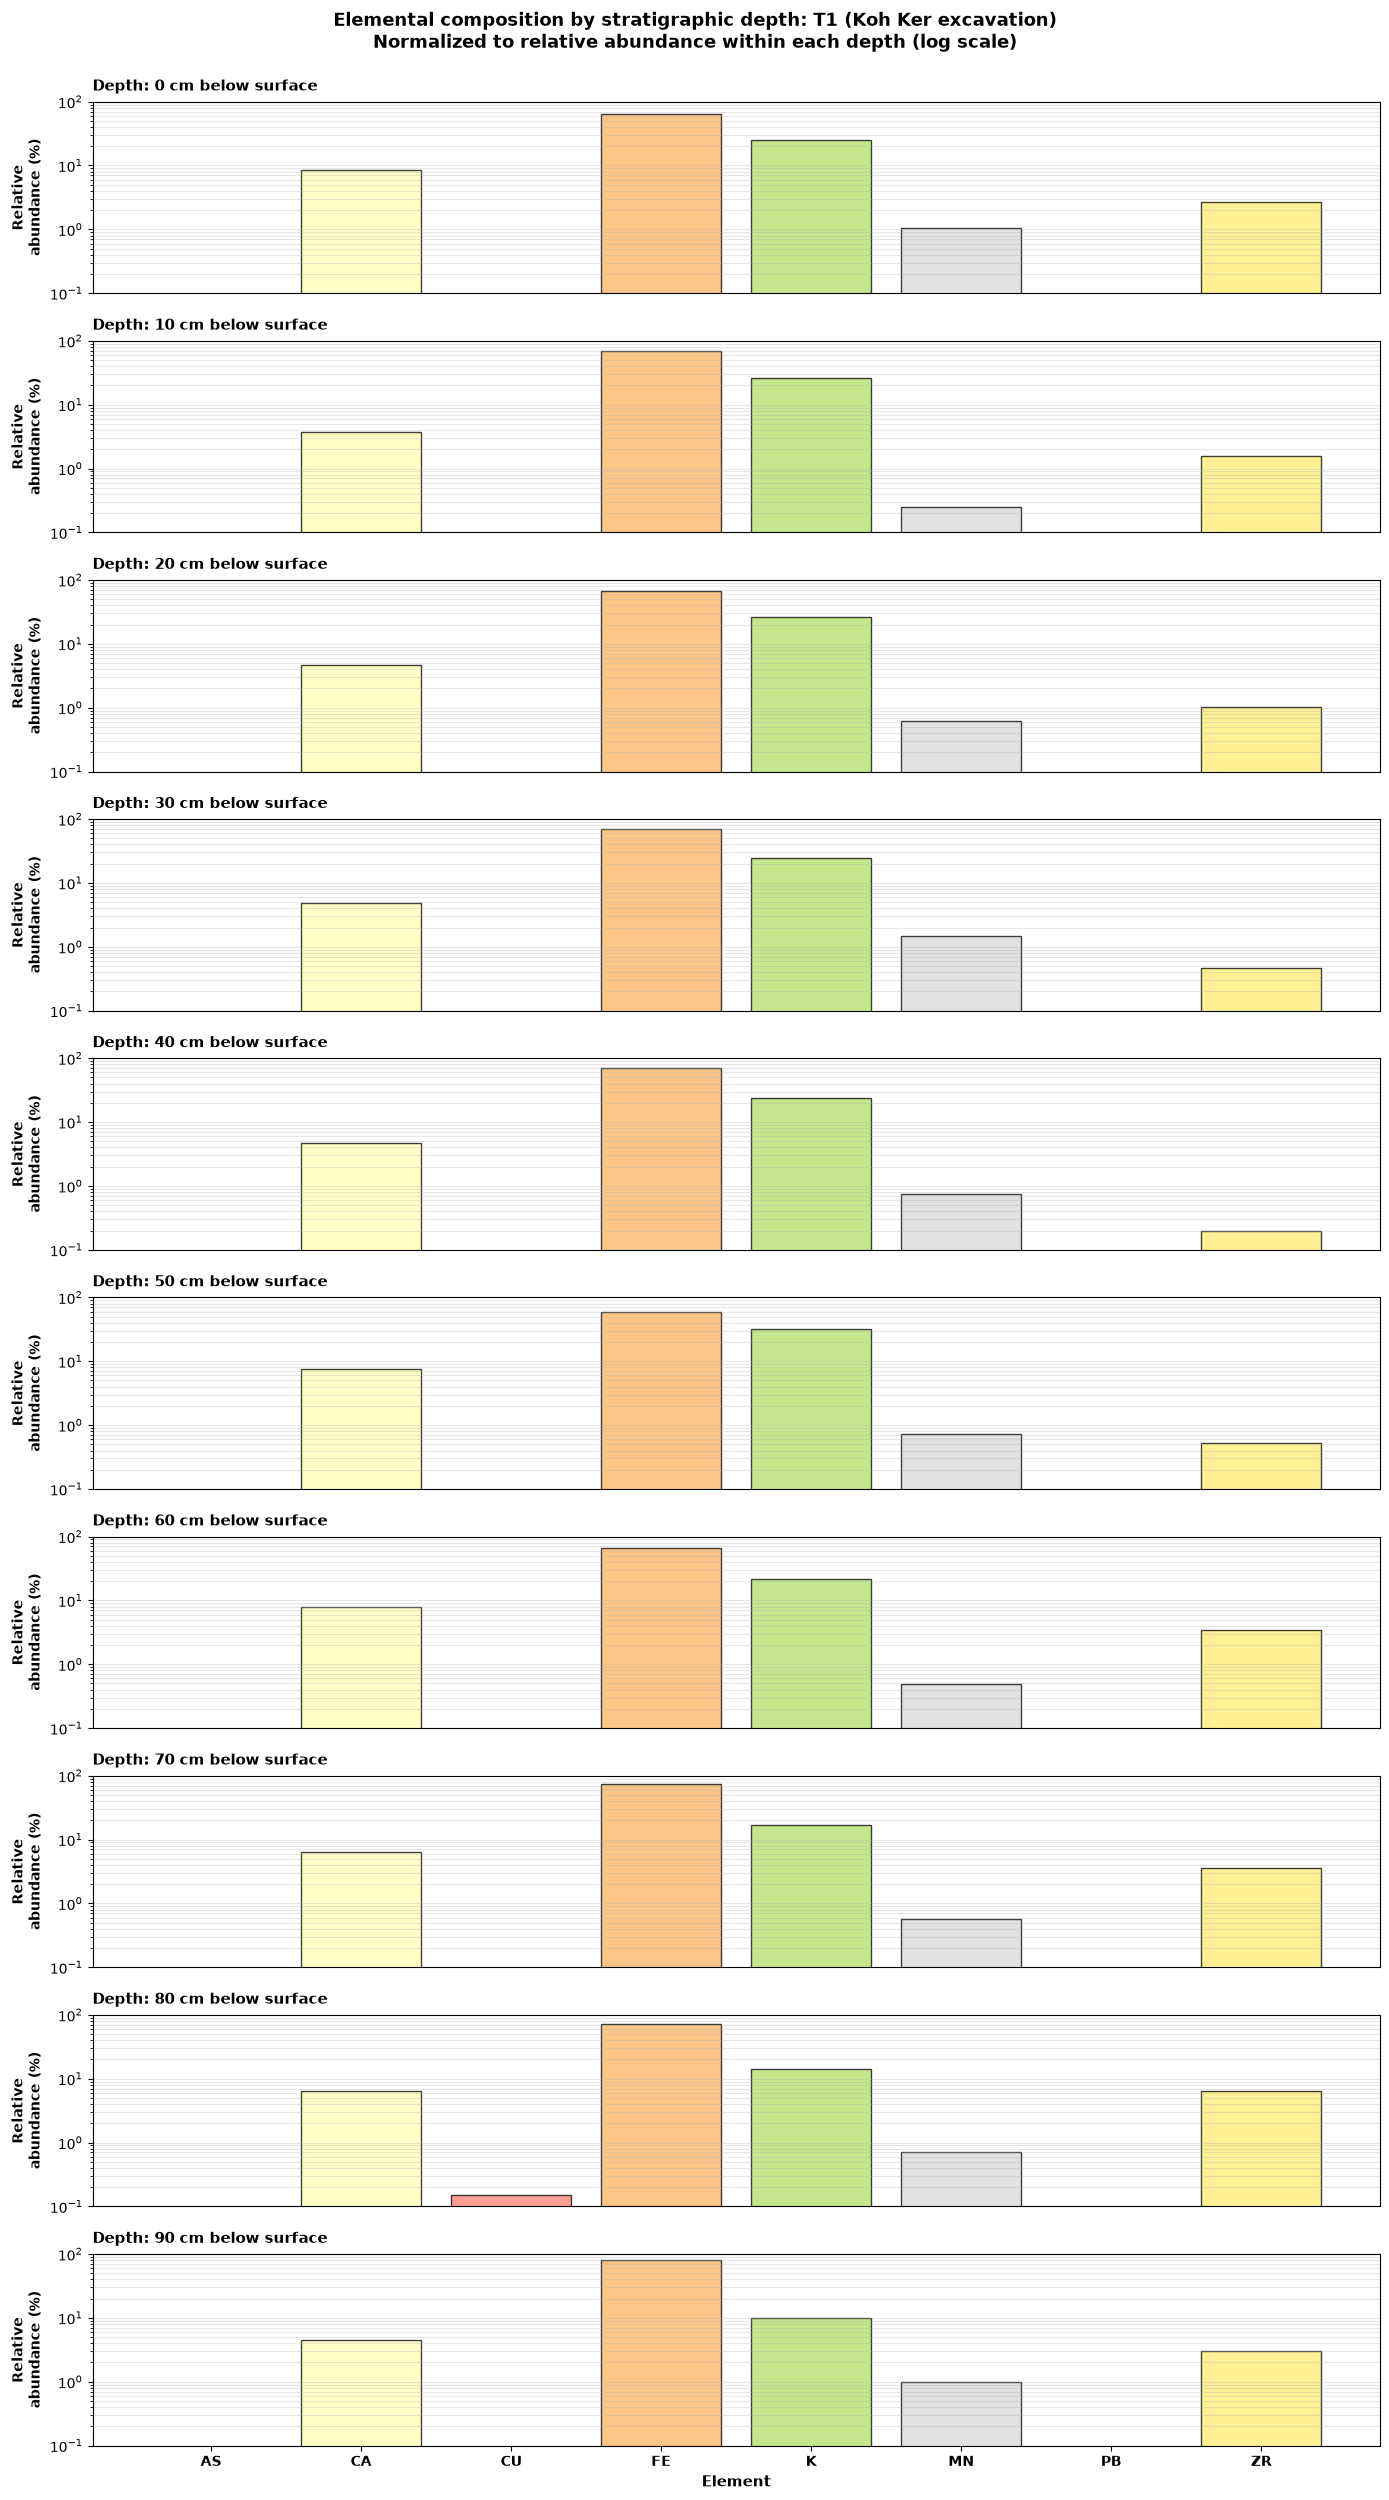

In [53]:
import matplotlib.pyplot as plt
import numpy as np

# Select a trench
selected_trench = "T1"
trench_data = df[(df["trench_unit"] == selected_trench) & (df["units"] == "ppm")].copy()

# Use log scale for y-axis to reveal trace elements
use_log_scale = True  # Set to False for linear scale

print(f"Analyzing: {selected_trench}")
print(f"Y-axis scale: {'logarithmic' if use_log_scale else 'linear'}")

# Get all depths for this trench
depths = sorted(trench_data["dbs_cm"].unique())
print(f"Depths sampled: {[int(d) for d in depths]} cm")
print(f"Number of depth samples: {len(depths)}")

# Define the consistent element suite
key_elements = ["fe", "ca", "k", "al", "si", "zr", "mn", "cu", "pb", "as"]

# Find union of elements with any non-zero values across all depths
elements_present = set()
for depth in depths:
    depth_data = trench_data[trench_data["dbs_cm"] == depth]
    for element in key_elements:
        element_values = pd.to_numeric(depth_data[element], errors="coerce")
        if (element_values > 0).any():
            elements_present.add(element)

elements_to_plot = sorted(list(elements_present))
print(f"Consistent element suite: {[e.upper() for e in elements_to_plot]}")

# Create subplots - one row per depth
fig, axes = plt.subplots(len(depths), 1, figsize=(14, 2.5*len(depths)))
if len(depths) == 1:
    axes = [axes]

for depth_idx, depth in enumerate(depths):
    depth_data = trench_data[trench_data["dbs_cm"] == depth]
    
    # Collect mean concentrations for all elements (including zeros)
    element_means = []
    for element in elements_to_plot:
        element_values = pd.to_numeric(depth_data[element], errors="coerce")
        if len(element_values.dropna()) > 0:
            element_means.append(element_values.mean())
        else:
            element_means.append(0.0)
    
    # Normalize to relative abundance (%)
    total = sum(element_means)
    if total > 0:
        element_means_norm = [v/total*100 for v in element_means]
    else:
        element_means_norm = [0.0] * len(elements_to_plot)
    
    ax = axes[depth_idx]
    x_pos = np.arange(len(elements_to_plot))
    bars = ax.bar(x_pos, element_means_norm, alpha=0.75, edgecolor="black", linewidth=1,
                   color=plt.cm.Set3(np.linspace(0, 1, len(elements_to_plot))))
    
    ax.set_ylabel("Relative\nabundance (%)", fontsize=10, fontweight="bold")
    
    # Apply log scale if enabled
    if use_log_scale:
        ax.set_yscale("log")
        ax.set_ylim(0.1, 100)
    else:
        ax.set_ylim(0, 100)
    
    ax.grid(True, alpha=0.3, axis="y", which="both")
    ax.set_title(f"Depth: {int(depth)} cm below surface", fontsize=11, fontweight="bold", loc="left", pad=8)
    
    # Only show x-axis labels on the bottom plot
    if depth_idx < len(depths) - 1:
        ax.set_xticks([])
    else:
        ax.set_xticks(x_pos)
        ax.set_xticklabels([e.upper() for e in elements_to_plot], fontsize=10, fontweight="bold")
        ax.set_xlabel("Element", fontsize=11, fontweight="bold")

scale_note = "(log scale)" if use_log_scale else "(linear scale)"
plt.suptitle(
    f"Elemental composition by stratigraphic depth: {selected_trench} (Koh Ker excavation)\nNormalized to relative abundance within each depth {scale_note}",
    fontsize=13, fontweight="bold", y=0.998
)
plt.tight_layout()
plt.show()

## Compare elements between soil and mining readings

Since soil and mining readings use different units (ppm vs %), they should not be directly compared. This section shows how to handle them separately.

In [54]:
# Extract selected elements for comparison
elements_to_check = ["fe", "ca", "zr", "cu"]

print("Soil readings (ppm) - selected elements:")
soil_elements = soil_readings[["reading_no", "sample"] + elements_to_check].head()
print(soil_elements)

print("\n\nMining readings (%) - selected elements:")
mining_elements = mining_readings[["reading_no", "sample"] + elements_to_check].head()
print(mining_elements)

print("\n⚠️  Note: These two sets of readings use different units and should not be directly compared.")

Soil readings (ppm) - selected elements:
   reading_no     sample        fe       ca      zr     cu
0          57   KKT1-0CM   9634.93  1296.67  412.64   <LOD
1          58   KKT1-0CM   9587.45   1301.9  407.17   <LOD
2          59   KKT1-0CM   9573.34  1289.53  410.63   <LOD
6          73  KKT1-10CM  18394.65  1002.96  420.07  17.63
7          74  KKT1-10CM  18435.24  1002.91  425.38  15.83


Mining readings (%) - selected elements:
    reading_no     sample     fe     ca     zr    cu
3           60   KKT1-0CM  1.472  0.195  0.032  <LOD
4           61   KKT1-0CM  1.416  0.195  0.032  <LOD
5           62   KKT1-0CM  1.401  0.185  0.032  <LOD
9           70  KKT1-10CM  2.612  0.154  0.042  <LOD
10          71  KKT1-10CM  2.591  0.152  0.041  <LOD

⚠️  Note: These two sets of readings use different units and should not be directly compared.


## Generate a summary report

Create a summary of available elements and their measurement statistics.

In [55]:
# Get list of unique elements (base names without _error or _cps_ua)
element_names = set()
for col in element_cols:
    base = col.rsplit("_", 1)[0] if "_error" in col or "_cps" in col else col
    if not any(x in col for x in ["_error", "_cps"]):
        element_names.add(col)

element_names = sorted(element_names)
print(f"Elements measured: {len(element_names)}")
print(f"\nElement list: {', '.join(element_names)}")

Elements measured: 46

Element list: ag, al, as, au, ba, bal, bi, ca, cd, cl, co, cr, cs, cu, dbs_cm, fe, hg, k, mg, mn, mo, nb, ni, notes, p, pb, pd, rb, s, sb, sc, se, si, site, sn, sr, te, th, ti, trench_unit, u, v, w, y, zn, zr


## Export processed results

Save the loaded data and processed results to CSV files for further analysis.

In [ ]:
# Keep processed results in memory by default.
# Set export_csv = True to write CSV files explicitly.
export_csv = False
if export_csv:
    output_full = Path("pxrf_demo_full.csv")
    df.to_csv(output_full, index=False)
    print(f"Saved full pXRF dataset to {output_full}")

    output_soil = Path("pxrf_demo_soil.csv")
    soil_readings.to_csv(output_soil, index=False)
    print(f"Saved soil readings (ppm) to {output_soil}")

    output_mining = Path("pxrf_demo_mining.csv")
    mining_readings.to_csv(output_mining, index=False)
    print(f"Saved mining readings (%) to {output_mining}")

Saved full pXRF dataset to /mnt/DCDCDB23DCDAF72C/wcarleton/Projects/MagSus/notebooks/output/pxrf_demo_full.csv
Saved soil readings (ppm) to /mnt/DCDCDB23DCDAF72C/wcarleton/Projects/MagSus/notebooks/output/pxrf_demo_soil.csv
Saved mining readings (%) to /mnt/DCDCDB23DCDAF72C/wcarleton/Projects/MagSus/notebooks/output/pxrf_demo_mining.csv


## Next steps

With the pXRF data loaded and explored:
- Filter by sample ID or test type for targeted analysis
- Combine with other datasets (magnetic susceptibility, etc.) for multi-method comparison
- Perform statistical analysis on elemental correlations
- Create geospatial visualizations if location data is available
- Detect anomalies or patterns in elemental concentrations